In [2]:
# ---------------------------------------------------------------------------
# Question 1.0 – Imports & Dataset Load
# ---------------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.model_selection import cross_val_score

from sklearn import svm
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

# ---------------------------------------------------------------------------
# Question 1.1 – Load Breast Cancer Data
# ---------------------------------------------------------------------------
BASE_DIR = Path(r"D:\GradSchool\DAAN862\Lesson10")
DATA_PATH = BASE_DIR / "dataR2.xlsx"

df = pd.read_excel(DATA_PATH)

print("\n" + "="*70)
print("Question 1.1 – Data Shape and Columns")
print("="*70)
print("Shape (rows, columns):", df.shape)
print("Columns:", list(df.columns))

print("\nFirst 5 rows:")
print(df.head())

print("\nSummary statistics:")
print(df.describe())

print("\nMissing values per column:")
print(df.isna().sum())


Question 1.1 – Data Shape and Columns
Shape (rows, columns): (116, 10)
Columns: ['Age', 'BMI', 'Glucose', 'Insulin', 'HOMA', 'Leptin', 'Adiponectin', 'Resistin', 'MCP.1', 'Classification']

First 5 rows:
   Age        BMI  Glucose  Insulin      HOMA   Leptin  Adiponectin  Resistin  \
0   48  23.500000       70    2.707  0.467409   8.8071     9.702400   7.99585   
1   83  20.690495       92    3.115  0.706897   8.8438     5.429285   4.06405   
2   82  23.124670       91    4.498  1.009651  17.9393    22.432040   9.27715   
3   68  21.367521       77    3.226  0.612725   9.8827     7.169560  12.76600   
4   86  21.111111       92    3.549  0.805386   6.6994     4.819240  10.57635   

     MCP.1  Classification  
0  417.114               1  
1  468.786               1  
2  554.697               1  
3  928.220               1  
4  773.920               1  

Summary statistics:
              Age         BMI     Glucose     Insulin        HOMA      Leptin  \
count  116.000000  116.000000  1


Question 1.2 – Class Distribution (Classification)
Classification
1    52
2    64
Name: count, dtype: int64


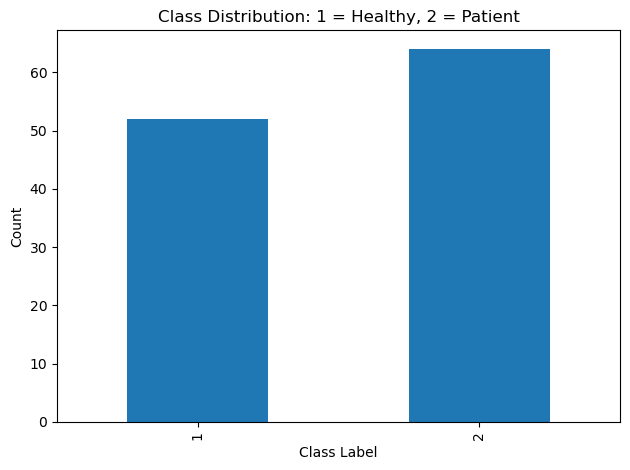

In [4]:

# ---------------------------------------------------------------------------
# Question 1.2 – Class Distribution
# ---------------------------------------------------------------------------
label_counts = df["Classification"].value_counts().sort_index()

print("\n" + "="*70)
print("Question 1.2 – Class Distribution (Classification)")
print("="*70)
print(label_counts)  # 1 = Healthy, 2 = Patient

# Bar chart of class balance (diagnostic plot style)
plt.figure()
label_counts.plot(kind='bar')
plt.title("Class Distribution: 1 = Healthy, 2 = Patient")
plt.xlabel("Class Label")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

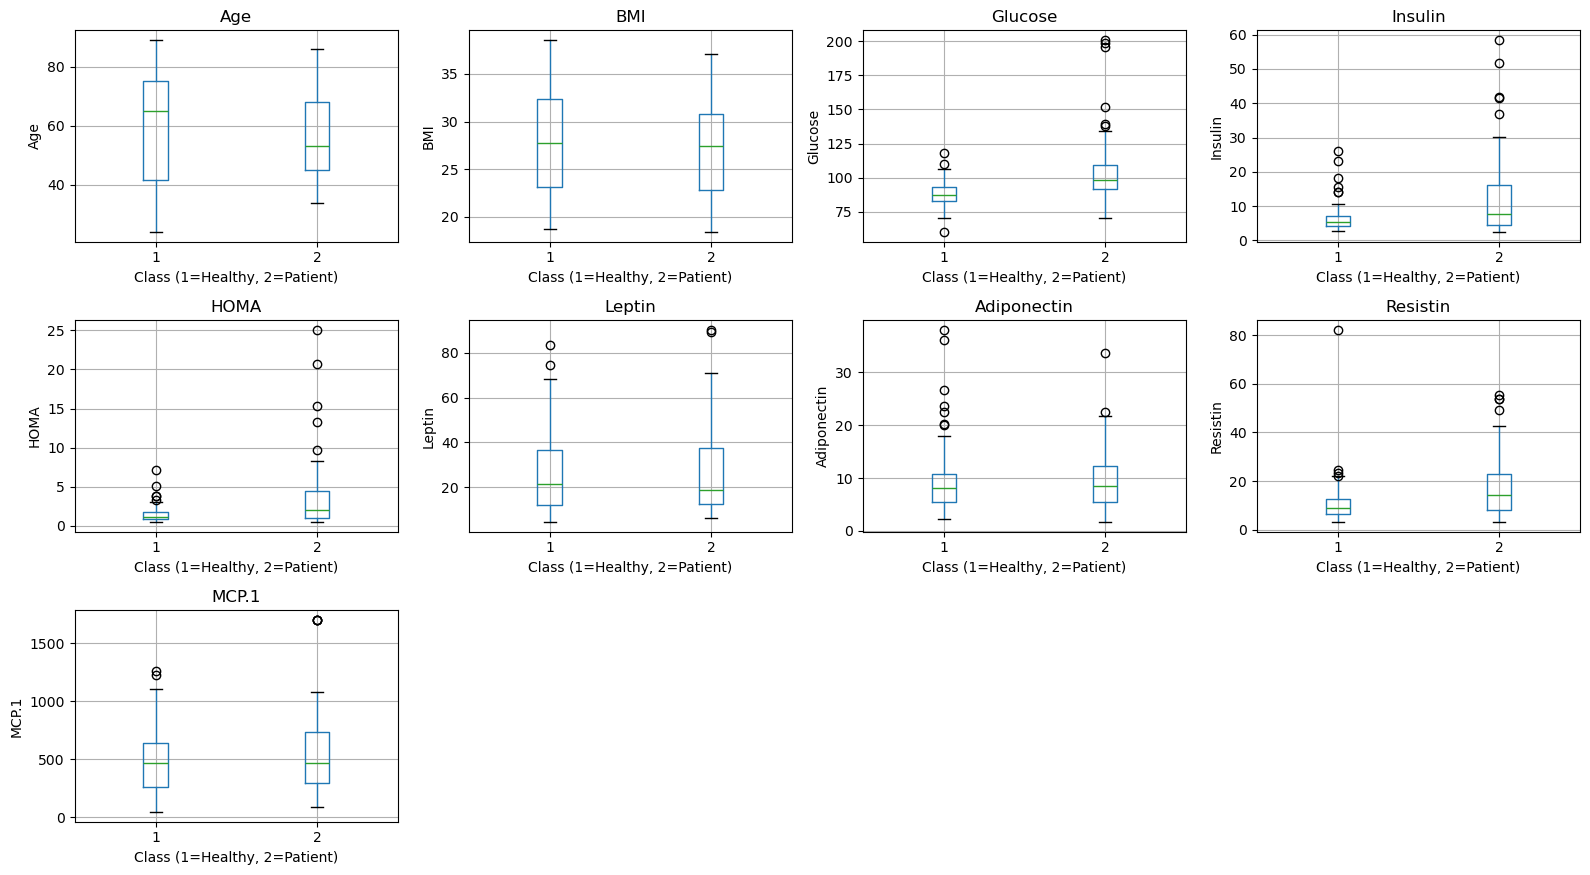


Question 1.3 – EDA Complete
Dataset explored: summary stats, class balance, and per-feature distribution by class.


In [11]:
# ---------------------------------------------------------------------------
# Question 1.3 – Feature vs Class (Boxplots)
# ---------------------------------------------------------------------------
# Grid of boxplots: each predictor vs Classification (1=Healthy,2=Patient)

features = [c for c in df.columns if c != "Classification"]

# We'll do a 3x4 layout so it's wide (4 columns per row)
n_cols = 4
n_rows = int(np.ceil(len(features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 9))
axes = axes.flatten()  # make it easy to index

for ax_idx, col in enumerate(features):
    ax = axes[ax_idx]

    # Use pandas built-in boxplot with 'by', but direct it to our ax
    df.boxplot(column=col, by="Classification", ax=ax)

    # Clean up titles/labels
    ax.set_title(col)
    ax.set_xlabel("Class (1=Healthy, 2=Patient)")
    ax.set_ylabel(col)

# Turn off any unused subplots (if features doesn't fill the grid)
for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

# Remove the automatic super-title that pandas.boxplot adds
plt.suptitle("")

plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("Question 1.3 – EDA Complete")
print("="*70)
print("Dataset explored: summary stats, class balance, and per-feature distribution by class.")


In [6]:
# ---------------------------------------------------------------------------
# Question 1.4 – Train/Test Split
# ---------------------------------------------------------------------------
X = df.drop(columns=["Classification"])
y = df["Classification"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=34
)

print("\n" + "="*70)
print("Question 1.4 – Train/Test Split")
print("="*70)
print("Training set size:", len(X_train))
print("Test set size:", len(X_test))


Question 1.4 – Train/Test Split
Training set size: 81
Test set size: 35



Question 2.0 – SVM Model Accuracy
Linear kernel accuracy:     0.743
RBF kernel accuracy:        0.514
Polynomial (degree=2) acc.: 0.514


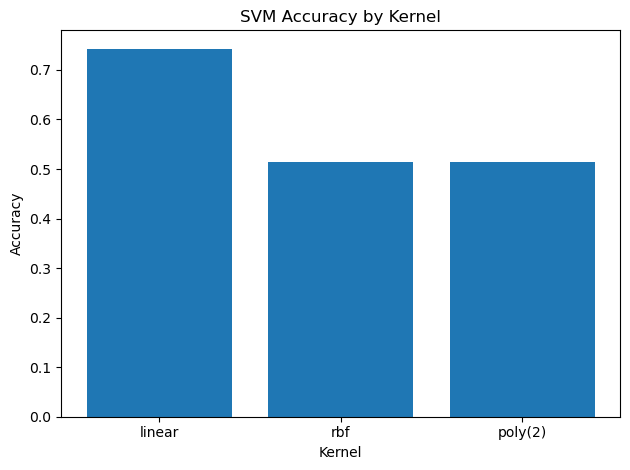

In [7]:
# ---------------------------------------------------------------------------
# Question 2.0 – Support Vector Machine Models (Different Kernels)
# ---------------------------------------------------------------------------
svm_linear = svm.SVC(kernel='linear')
svm_linear.fit(X_train, y_train)
svm_linear_pred = svm_linear.predict(X_test)
svm_linear_acc = metrics.accuracy_score(y_test, svm_linear_pred)

svm_rbf = svm.SVC(kernel='rbf', gamma=0.1)
svm_rbf.fit(X_train, y_train)
svm_rbf_pred = svm_rbf.predict(X_test)
svm_rbf_acc = metrics.accuracy_score(y_test, svm_rbf_pred)

svm_poly = svm.SVC(kernel='poly', degree=2)
svm_poly.fit(X_train, y_train)
svm_poly_pred = svm_poly.predict(X_test)
svm_poly_acc = metrics.accuracy_score(y_test, svm_poly_pred)

print("\n" + "="*70)
print("Question 2.0 – SVM Model Accuracy")
print("="*70)
print(f"Linear kernel accuracy:     {svm_linear_acc:.3f}")
print(f"RBF kernel accuracy:        {svm_rbf_acc:.3f}")
print(f"Polynomial (degree=2) acc.: {svm_poly_acc:.3f}")

plt.figure()
plt.bar(['linear', 'rbf', 'poly(2)'],
        [svm_linear_acc, svm_rbf_acc, svm_poly_acc])
plt.title('SVM Accuracy by Kernel')
plt.ylabel('Accuracy')
plt.xlabel('Kernel')
plt.tight_layout()
plt.show()



Best n_estimator for Random Forest Model
Best n_estimator = 6
Cross-val Accuracy = 0.715


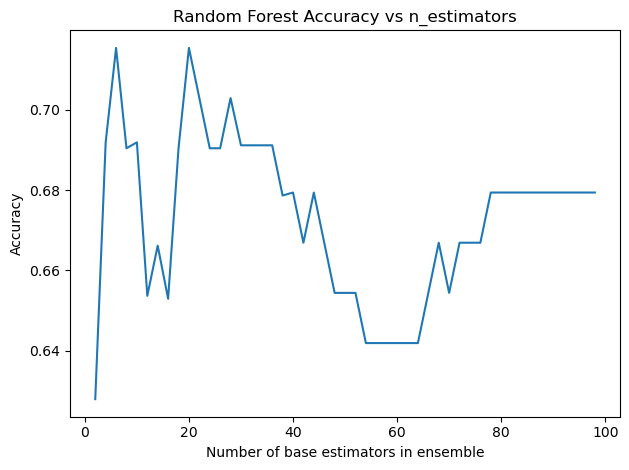

In [8]:
# ---------------------------------------------------------------------------
# Question 3.0 – Random Forest: Accuracy vs n_estimators
# ---------------------------------------------------------------------------
n_estimator_rf = range(2, 100, 2)
accuracy_rf = []

for i in n_estimator_rf:
    RF = RandomForestClassifier(n_estimators=i, random_state=0)
    scores = cross_val_score(RF, X_train, y_train)
    accuracy_rf.append(scores.mean())

best_index_rf = int(np.argmax(accuracy_rf))
best_n_rf = list(n_estimator_rf)[best_index_rf]
best_rf_acc = accuracy_rf[best_index_rf]

print("\n" + "="*70)
print("Best n_estimator for Random Forest Model")
print("="*70)
print(f"Best n_estimator = {best_n_rf}")
print(f"Cross-val Accuracy = {best_rf_acc:.3f}")

plt.figure()
plt.plot(list(n_estimator_rf), accuracy_rf)
plt.title('Random Forest Accuracy vs n_estimators')
plt.ylabel('Accuracy')
plt.xlabel('Number of base estimators in ensemble')
plt.tight_layout()
plt.show()


Best n_estimator for AdaBoost Model
Best n_estimator = 1
Cross-val Accuracy = 0.656


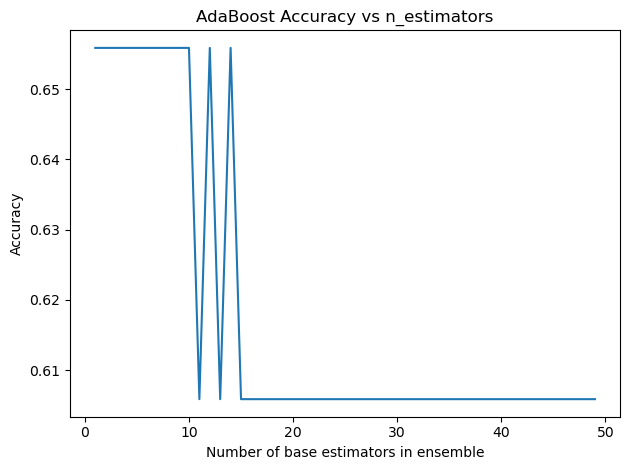

In [9]:
# ---------------------------------------------------------------------------
# Question 4.0 – AdaBoost: Accuracy vs n_estimators
# ---------------------------------------------------------------------------
n_estimator_ada = range(1, 50, 1)
accuracy_ada = []

for i in n_estimator_ada:
    Ada = AdaBoostClassifier(
        n_estimators=i,
        learning_rate=0.005,
        random_state=21
    )
    scores = cross_val_score(Ada, X_train, y_train)
    accuracy_ada.append(scores.mean())

best_index_ada = int(np.argmax(accuracy_ada))
best_n_ada = list(n_estimator_ada)[best_index_ada]
best_ada_acc = accuracy_ada[best_index_ada]

print("\n" + "="*70)
print("Best n_estimator for AdaBoost Model")
print("="*70)
print(f"Best n_estimator = {best_n_ada}")
print(f"Cross-val Accuracy = {best_ada_acc:.3f}")

plt.figure()
plt.plot(list(n_estimator_ada), accuracy_ada)
plt.title('AdaBoost Accuracy vs n_estimators')
plt.ylabel('Accuracy')
plt.xlabel('Number of base estimators in ensemble')
plt.tight_layout()
plt.show()


Question 4.1 – AdaBoost Learning Rate Sensitivity
Best learning_rate = 0.001
Cross-val Accuracy = 0.656


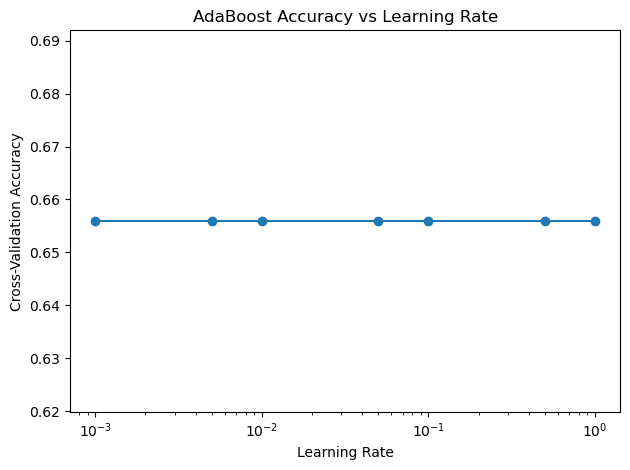

In [10]:
# ---------------------------------------------------------------------------
# Question 4.1 – AdaBoost Learning Rate Sensitivity
# ---------------------------------------------------------------------------

learning_rates = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0]
accuracy_lr = []

for lr in learning_rates:
    Ada = AdaBoostClassifier(
        n_estimators=best_n_ada,
        learning_rate=lr,
        random_state=21
    )
    scores = cross_val_score(Ada, X_train, y_train)
    accuracy_lr.append(scores.mean())

best_index_lr = int(np.argmax(accuracy_lr))
best_lr = learning_rates[best_index_lr]
best_lr_acc = accuracy_lr[best_index_lr]

print("\n" + "="*70)
print("Question 4.1 – AdaBoost Learning Rate Sensitivity")
print("="*70)
print(f"Best learning_rate = {best_lr}")
print(f"Cross-val Accuracy = {best_lr_acc:.3f}")

plt.figure()
plt.plot(learning_rates, accuracy_lr, marker='o')
plt.title('AdaBoost Accuracy vs Learning Rate')
plt.ylabel('Cross-Validation Accuracy')
plt.xlabel('Learning Rate')
plt.xscale('log')  # easier to view wide range
plt.tight_layout()
plt.show()
